# random forest house prices

người thực hiện: như

ngày: 15/11/2026

chạy mới: baseline, cải tiến đặc trưng và siêu tham số, phân tích sai số, dự đoán test.

## 1. câu hỏi nghiên cứu

xử lý NA theo ý nghĩa và thêm đặc trưng diện tích, tuổi nhà, tiện ích có giảm sai số rf không? giới hạn độ sâu và tăng kích thước lá có giảm khoảng cách train–validation không? kiểm chứng bằng cv, chấp nhận cả phương án tăng sai số.

## 2. dữ liệu và môi trường

train có nhãn SalePrice; test chỉ dùng xuất dự đoán. loại Id khỏi đầu vào, huấn luyện log tự nhiên của SalePrice. dùng cùng danh sách Id và fold đã có trong project.

In [1]:
from pathlib import Path
import sys
from IPython.display import display
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in (p, p / 'Challenge/Challenge1')]
root = next(p for p in candidates if (p / 'data/raw/train.csv').is_file())
sys.path.insert(0, str(root / 'members/Nhu/src'))
import rf_workflow as rf
run, train, test, dev, hold, folds = rf.setup()


ngày chạy: 15/11/2026
train: (1460, 81) | test: (1459, 80)
development: 1168 | holdout: 292 | features gốc: 79
python: 3.12.14 | sklearn: 1.9.1
kết quả: C:\Users\LEGION\Desktop\github\Machine-learning\Challenge\Challenge1\members\Nhu\outputs\experiments\20261115_171330_237145


## 3. eda trên development

kiểm tra giá, log giá, thiếu dữ liệu và quan hệ diện tích–giá. giữ nguyên holdout trong giai đoạn nghiên cứu. NA chỉ đổi thành absent ở các thuộc tính mà từ điển ghi là không có tiện ích; các giá trị chưa biết còn lại được điền trong từng fold.

chỉ EDA development; giữ nguyên ngoại lệ, không xóa theo điểm holdout


<Figure size 1200x800 with 4 Axes>

PoolQC          0.995719
MiscFeature     0.968322
Alley           0.937500
Fence           0.808219
MasVnrType      0.588185
FireplaceQu     0.465753
LotFrontage     0.176370
GarageType      0.059932
GarageQual      0.059932
GarageFinish    0.059932
GarageCond      0.059932
GarageYrBlt     0.059932
dtype: float64

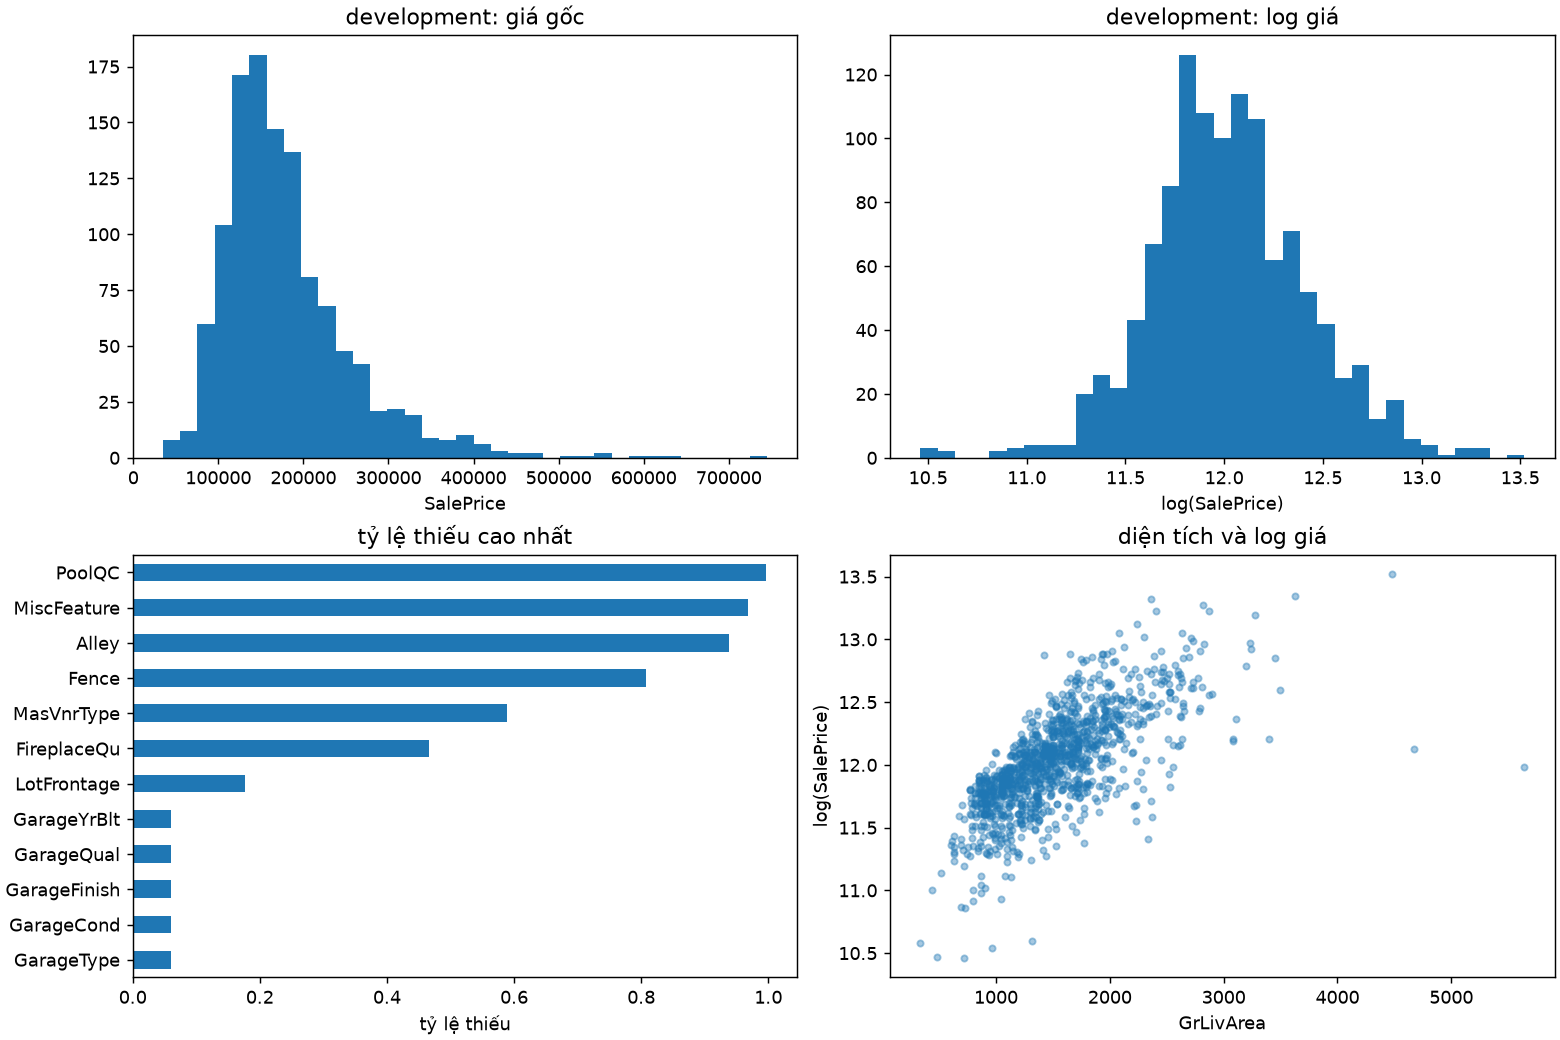

In [2]:
missing = rf.eda(dev, run)
display(missing)


## 4. protocol và sáu cấu hình

development 80%, holdout 20%, seed 7. cv 5 fold shuffle seed 7 trên development. imputer và encoder nằm trong pipeline; rf không cần scale. các phương án cố định trước khi chạy: baseline; xử lý NA theo nghĩa; thêm feature; depth 12; leaf 3; depth 12 kết hợp leaf 3. mọi phương án giữ 100 cây. sd là độ lệch chuẩn mẫu giữa 5 fold, không phải khoảng tin cậy.

In [3]:
display(rf.pd.DataFrame(rf.TRIALS, columns=["exp_id", "features", "max_depth", "min_samples_leaf", "hypothesis"]))
print(rf.pipeline("baseline").get_params()["rf"])


RandomForestRegressor(n_jobs=2, random_state=7)


        exp_id  ...                                         hypothesis
0  Nhu_EXP-001  ...          mốc rf với điền thiếu trung vị và one-hot
1  Nhu_EXP-002  ...  phân biệt không có tiện ích với giá trị chưa biết
2  Nhu_EXP-003  ...  thêm diện tích, tuổi nhà và tiện ích so với ex...
3  Nhu_EXP-004  ...                      giới hạn độ sâu so với exp003
4  Nhu_EXP-005  ...                   tăng kích thước lá so với exp003
5  Nhu_EXP-006  ...      kết hợp độ sâu và lá; so với exp004 và exp005

[6 rows x 5 columns]

## 5. thực thi và chọn bằng cv

không dùng holdout để chọn cấu hình. lưu điểm từng fold, dự đoán oof và cấu hình đã chọn trước khi đánh giá holdout.

In [4]:
comparison, selected = rf.run_trials(dev, folds, run)
display(comparison)
print("cấu hình chọn bằng cv:", selected)


Nhu_EXP-001 fold 1/5 rmse=0.15409
Nhu_EXP-001 fold 2/5 rmse=0.13938
Nhu_EXP-001 fold 3/5 rmse=0.17792
Nhu_EXP-001 fold 4/5 rmse=0.15118
Nhu_EXP-001 fold 5/5 rmse=0.12521
Nhu_EXP-002 fold 1/5 rmse=0.15562
Nhu_EXP-002 fold 2/5 rmse=0.14082
Nhu_EXP-002 fold 3/5 rmse=0.17747
Nhu_EXP-002 fold 4/5 rmse=0.15076
Nhu_EXP-002 fold 5/5 rmse=0.12605
Nhu_EXP-003 fold 1/5 rmse=0.14353
Nhu_EXP-003 fold 2/5 rmse=0.13755
Nhu_EXP-003 fold 3/5 rmse=0.18078
Nhu_EXP-003 fold 4/5 rmse=0.13951
Nhu_EXP-003 fold 5/5 rmse=0.12453
Nhu_EXP-004 fold 1/5 rmse=0.14449
Nhu_EXP-004 fold 2/5 rmse=0.13769
Nhu_EXP-004 fold 3/5 rmse=0.17919
Nhu_EXP-004 fold 4/5 rmse=0.14063
Nhu_EXP-004 fold 5/5 rmse=0.12476
Nhu_EXP-005 fold 1/5 rmse=0.14527
Nhu_EXP-005 fold 2/5 rmse=0.13699
Nhu_EXP-005 fold 3/5 rmse=0.18437
Nhu_EXP-005 fold 4/5 rmse=0.13672
Nhu_EXP-005 fold 5/5 rmse=0.12351
Nhu_EXP-006 fold 1/5 rmse=0.14539
Nhu_EXP-006 fold 2/5 rmse=0.13654
Nhu_EXP-006 fold 3/5 rmse=0.18419
Nhu_EXP-006 fold 4/5 rmse=0.13696
Nhu_EXP-006 fo

        exp_id        date member  ...  cv_mae_price   seconds  warning_folds
0  Nhu_EXP-001  15/11/2026    như  ...  18159.158010  3.315171              0
1  Nhu_EXP-002  15/11/2026    như  ...  18130.045813  3.509188              0
2  Nhu_EXP-003  15/11/2026    như  ...  17549.727072  3.713930              0
3  Nhu_EXP-004  15/11/2026    như  ...  17521.440620  3.419461              0
4  Nhu_EXP-005  15/11/2026    như  ...  17637.511530  2.907235              0
5  Nhu_EXP-006  15/11/2026    như  ...  17610.664120  2.823885              0

[6 rows x 16 columns]

## 6. so sánh cải tiến

đối chiếu exp002 với exp001 để đánh giá xử lý NA và kiểu mã nhà; exp003 với exp002 để đánh giá nhóm feature mới. exp004 và exp005 so với exp003 để tách ảnh hưởng depth và leaf. exp006 kiểm tra kết hợp. so sánh theo từng fold, không chỉ lấy một điểm đẹp.

<Figure size 1000x400 with 1 Axes>

        exp_id  cv_rmse_mean  cv_rmse_std  delta_vs_baseline
0  Nhu_EXP-001      0.149557     0.019518           0.000000
1  Nhu_EXP-002      0.150144     0.019001           0.000587
2  Nhu_EXP-003      0.145180     0.021134          -0.004377
3  Nhu_EXP-004      0.145353     0.020317          -0.004204
4  Nhu_EXP-005      0.145372     0.023150          -0.004185
5  Nhu_EXP-006      0.145329     0.023084          -0.004228

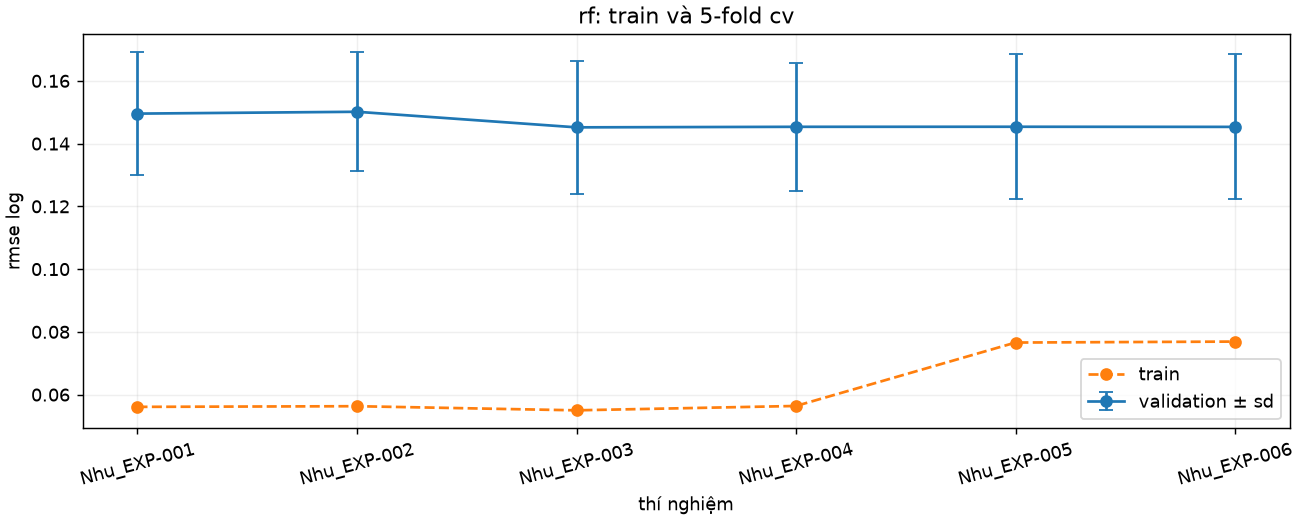

In [5]:
rf.plot_comparison(comparison, run)
delta = comparison[["exp_id", "cv_rmse_mean", "cv_rmse_std"]].copy()
delta["delta_vs_baseline"] = delta.cv_rmse_mean - comparison.iloc[0].cv_rmse_mean
display(delta)


## 7. holdout, sai số và importance

chỉ đánh giá cấu hình đã chốt bằng cv; không quay lại chọn tham số theo holdout. phần dư log dương là dự đoán thấp hơn giá thật. importance giảm impurity tổng hợp các cột one-hot về feature gốc, lấy trung bình từ 5 train fold; không phải quan hệ nhân quả.

{'exp_id': 'Nhu_EXP-003', 'n_holdout': 292, 'rmse_log': 0.13307417594501972, 'mae_price': 16825.30459995966, 'development_train_rmse_log': 0.054034478808702914, 'used_for_selection': False}


<Figure size 1100x400 with 2 Axes>

<Figure size 900x600 with 1 Axes>

              n     mae_price  mean_residual_log
price_band                                      
<150k       123  11120.120136          -0.046909
150k–250k   117  15292.264323           0.027072
>250k        52  33769.600782           0.075100

     Id      SalePrice
0  1461  123096.135709
1  1462  157952.089598
2  1463  177461.605237
3  1464  179984.255955
4  1465  191535.323889

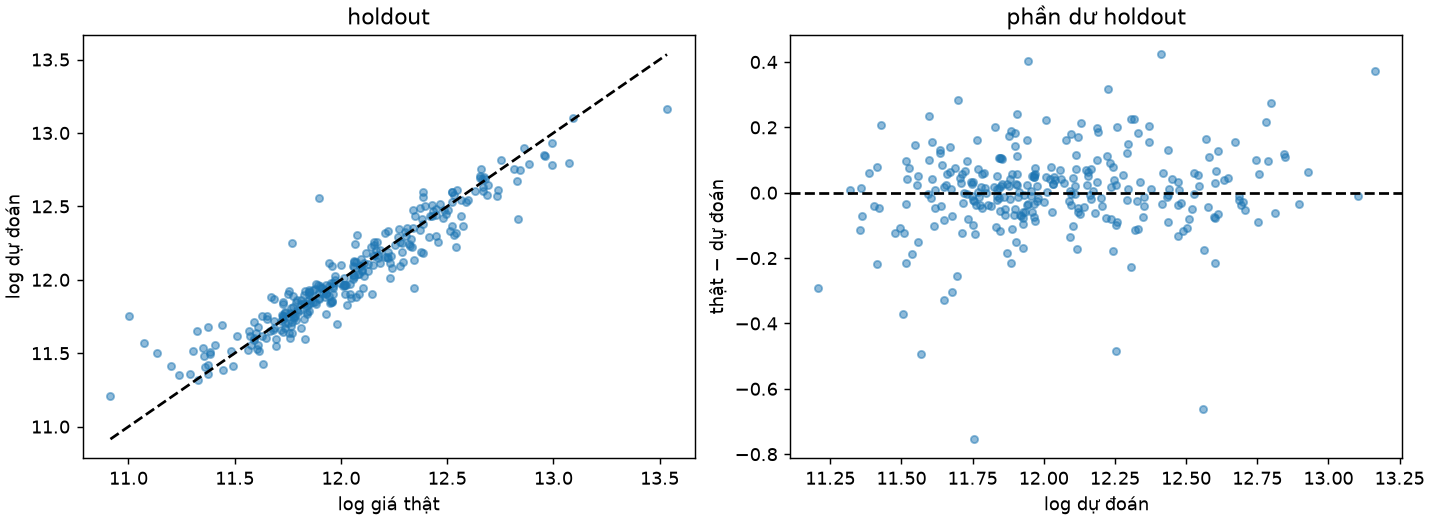

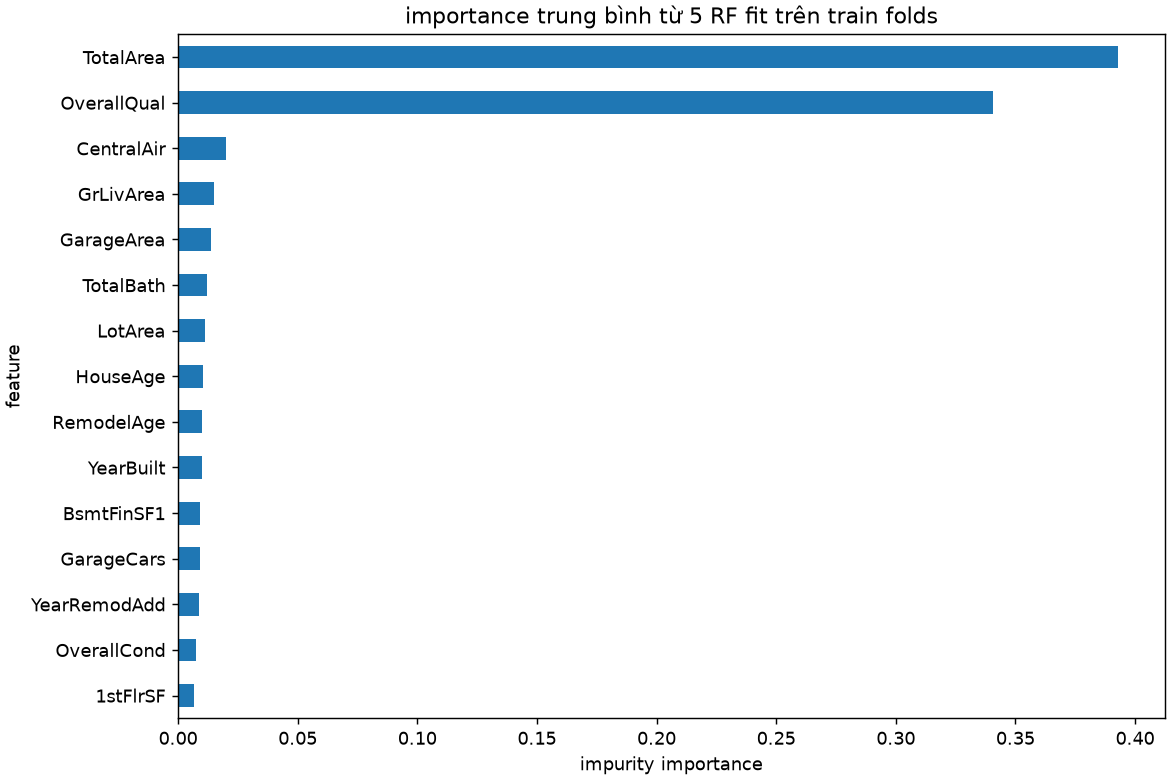

In [6]:
holdout_report, error_groups, submission_preview = rf.finish(train, test, dev, hold, selected, comparison, run)
print(holdout_report)
display(error_groups)
display(submission_preview)


## 8. dự đoán cuối và kiểm tra chạy lại

fit lại cấu hình đã chọn trên toàn bộ 1.460 nhà; xuất 1.459 dự đoán, kiểm tra thứ tự Id và giá dương. nạp lại pipeline đã lưu để đối chiếu dự đoán. kiểm tra này là chạy lại inference, không tuyên bố đã train độc lập lần hai.

In [7]:
rf.verify(run)


kiểm tra đạt: 6 thí nghiệm, 30 fold, 1.459 dự đoán; nạp model chạy lại khớp


## 9. kết luận và nhật ký

đọc số đo thực tế bên dưới. chưa nộp Kaggle, không có điểm leaderboard. lịch sử lần này được lưu riêng, không gán ngày cũ và không tạo lỗi giả. có thể làm tiếp ablation từng nhóm feature, permutation importance trong cv và khảo sát max_features; không dùng holdout để tối ưu thêm.

In [8]:
print((root / "reports/individual/Nhu_RF_report.md").read_text(encoding="utf-8"))
print("nguồn kết quả:", run)


# random forest house prices — như

Ngày thực hiện: 15/11/2026.

Dự đoán SalePrice từ 79 thuộc tính gốc; bỏ Id khỏi X. Train có 1.460 nhà,
development 1.168 và holdout 292 nhà theo split seed 7 của nhóm.
Huấn luyện bằng log tự nhiên của giá, chuyển lại bằng exp khi tính MAE và xuất dự đoán.

## giả thuyết và phương pháp

Kiểm tra xử lý NA theo ý nghĩa, đặc trưng diện tích/tuổi nhà/tiện ích và giới hạn
độ sâu hoặc kích thước lá có giảm sai số so với RF cơ sở không.
Mỗi fold tự fit imputer và one-hot. RF không cần chuẩn hóa. Không loại ngoại lệ,
không fit preprocessing trên holdout hoặc test. So sánh sáu phương án đã định trước,
chọn bằng 5-fold CV; độ lệch chuẩn mẫu dùng ddof=1.

| thí nghiệm | đặc trưng | cv rmse log ± sd | cv mae giá |
|---|---|---:|---:|
| Nhu_EXP-001 | baseline | 0.14956 ± 0.01952 | 18,159 |
| Nhu_EXP-002 | semantic | 0.15014 ± 0.01900 | 18,130 |
| Nhu_EXP-003 | engineered | 0.14518 ± 0.02113 | 17,550 |
| Nhu_EXP-004 | engineered | 0.14535 ± 0.02032 | 17,521 |
| Nhu

## 10. phần phối hợp nhóm

đã thêm sáu lượt rf vào nhật ký chung và nhập các số đo đã có từ nhật ký Nam. giữ nguyên dòng cũ của Mai và Thái. bảng results/group_model_comparison.csv ghi nguồn từng mô hình; reports/group_comparison_notes.md nêu giới hạn về hash dữ liệu và phiên bản môi trường. không coi việc tổng hợp là đã train lại trên máy khác.
